In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import math
import tiktoken

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

In [ ]:
BATCH_SIZE = 8
BLOCK_SIZE = 256
max_iters = 5000
lr = 3e-4

n_embed = 256
n_head = 4
n_layer = 6
dropout=0.2
head_size = 64

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [ ]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-19 13:24:44--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-10-19 13:24:44 (33.3 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [ ]:
with open('input.txt', 'r', encoding='utf-8') as file:
    text = file.read()

In [ ]:
print('length of the text:', len(text))

length of the text: 1115394


In [ ]:
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [ ]:
chars = sorted(set(text))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [ ]:
word2idx = {el:i for i, el in enumerate(chars)}
idx2word = {i:el for i, el in enumerate(chars)}

In [ ]:
encode = lambda s: [word2idx[c] for c in s]
decode = lambda s: ''.join([idx2word[c] for c in s])

In [ ]:
print(encode('hello world'))

[46, 43, 50, 50, 53, 1, 61, 53, 56, 50, 42]


ChatGPT использует токенизатор tiktoken

In [ ]:
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.type)
print(data[:1000])

torch.Size([1115394]) <built-in method type of Tensor object at 0x7e99daded770>
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59,  1, 39, 56, 43,  1, 39, 50, 50,
         1, 56, 43, 57, 53, 50, 60, 43, 42,  1, 56, 39, 58, 46, 43, 56,  1, 58,
        53,  1, 42, 47, 43,  1, 58, 46, 39, 52,  1, 58, 53,  1, 44, 39, 51, 47,
        57, 46, 12,  0,  0, 13, 50, 50, 10,  0, 30, 43, 57, 53, 50, 60, 43, 42,
         8,  1, 56, 43, 57, 53, 50, 60, 43, 42,  8,  0,  0, 18, 47, 56, 57, 58,
         1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 18, 47, 56, 57, 58,  6,  1, 63,
        53, 59,  1, 49, 52, 53, 61,  1, 

In [ ]:
# У нас есть датасет, делим его на test_size=0.1
n = int(len(data) * 0.9)
train_data = data[:n]
valid_data = data[n:]

In [ ]:
# Теперь нам нужно разбить на батчи
block_size = 8
print(train_data[:block_size+1])

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])


In [ ]:
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for i in range(block_size):
    context = x[:i + 1]
    target = y[i]
    print(f'input: {context} output: {target}')

input: tensor([18]) output: 47
input: tensor([18, 47]) output: 56
input: tensor([18, 47, 56]) output: 57
input: tensor([18, 47, 56, 57]) output: 58
input: tensor([18, 47, 56, 57, 58]) output: 1
input: tensor([18, 47, 56, 57, 58,  1]) output: 15
input: tensor([18, 47, 56, 57, 58,  1, 15]) output: 47
input: tensor([18, 47, 56, 57, 58,  1, 15, 47]) output: 58


In [ ]:
def get_batch(split):
    data = train_data if split == 'train' else valid_data
    idx = torch.randint(len(data) - BLOCK_SIZE, (BATCH_SIZE,)) # генерируем 4 случайных числа для нахождения начала предложения
    # вычитаем block_size, чтобы допустим [1,2,3,4,5,6,7,8,9,10] при i=2 можно было взять [2:9] числа и предсказать число 9
    x = torch.stack([data[i:i+BLOCK_SIZE] for i in idx])
    y = torch.stack([data[i+1:i+BLOCK_SIZE+1] for i in idx])
    return x, y

xb, yb = get_batch('train')

# for b in range(BATCH_SIZE):
#     for t in range(BLOCK_SIZE):
#         context = xb[b, :t+1]
#         target = yb[b, t]
#         print(f'input: {context} output: {target}')

In [ ]:
class GPTDataset(Dataset):
    def __init__(self, tokens, block_size):
        self.tokens = tokens
        self.block_size = block_size

    def __len__(self):
        return max(0, (len(self.tokens) - self.block_size - 1) // self.block_size + 1)

    def __getitem__(self, index):
        start = index * self.block_size
        chunk = self.tokens[start:start + self.block_size + 1]
        chunk = torch.tensor(np.asarray(chunk).astype(np.int64))

        x = chunk[:-1]
        y = chunk[1:]

        return x, y

In [ ]:
from google.colab import drive
from pathlib import Path
import json

drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/medical_articles.jsonl'

with open(DATA_PATH, 'r', encoding='utf-8') as file:
    articles = [json.loads(line) for line in file if line.strip()]

print(Path(DATA_PATH).exists())  # True

Mounted at /content/drive
True


In [ ]:
train_articles, valid_articles = train_test_split(articles, test_size=0.1, random_state=42, shuffle=True)
print(len(train_articles))
print(len(valid_articles))

2700
300


In [ ]:
tokenizer = tiktoken.get_encoding('gpt2')
vocab_size = tokenizer.n_vocab
print(vocab_size)

50257


In [ ]:
def tokenize(articles):
    tokens = []

    for article in articles:
        text = article['text'].strip()

        ids = tokenizer.encode_ordinary(text)
        tokens.extend(ids)
        tokens.append(tokenizer.eot_token)
    return tokens

train_tokens = tokenize(train_articles)
val_tokens = tokenize(valid_articles)

In [ ]:
train_dataset = GPTDataset(train_tokens, BLOCK_SIZE)
valid_dataset = GPTDataset(val_tokens, BLOCK_SIZE)

In [ ]:
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [ ]:
xb, yb = next(iter(train_dataloader))
print("X:", xb.shape)
print("Y:", yb.shape)

assert torch.equal(xb[:, 1:], yb[:, :-1])

X: torch.Size([8, 256])
Y: torch.Size([8, 256])


In [ ]:
# реализация головы или же self-attention
class Head(nn.Module):
    def __init__(self, head_size):
        super(Head, self).__init__()
        self.query = nn.Linear(n_embed, head_size, bias=False)
        self.key = nn.Linear(n_embed, head_size, bias=False)
        self.value = nn.Linear(n_embed, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(BLOCK_SIZE, BLOCK_SIZE)))
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)
        d_k = q.size(-1)

        scores = torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(d_k)
        mask = self.tril[:T, :T]

        scores = scores.masked_fill(mask == 0, float('-inf'))
        p_attn = F.softmax(scores, dim=-1)
        p_attn = self.dropout(p_attn)

        out = torch.matmul(p_attn, v)
        return out

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super(MultiHeadAttention, self).__init__()
        self.heads = nn.ModuleList([Head(head_size) for i in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embed)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, n_embed):
        super(FeedForward, self).__init__()
        self.w1 = nn.Linear(n_embed, 4 * n_embed)
        self.w2 = nn.Linear(4 * n_embed, n_embed)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x):
        out = self.w2(self.dropout(self.w1(x).relu()))
        return out

In [ ]:
class GPTBlock(nn.Module):
    def __init__(self, n_embed, n_head):
        super(GPTBlock, self).__init__()
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffn = FeedForward(n_embed)
        self.ln1 = nn.LayerNorm(n_embed)
        self.ln2 = nn.LayerNorm(n_embed)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

In [ ]:
class GPT2(nn.Module):
    def __init__(self):
        super(GPT2, self).__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embed)
        self.positional_embedding = nn.Embedding(BLOCK_SIZE, n_embed)
        self.blocks = nn.Sequential(*[GPTBlock(n_embed, n_head) for i in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embed)
        self.lm_head = nn.Linear(n_embed, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.positional_embedding(torch.arange(T, device=idx.device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def _init_weights(self, module): # будем изанчально задавать веса модели из гауссовского распределения
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def generate(self, idx, max_new_tokens): #авторегрессивно генерируем токены
        for i in range(max_new_tokens):
            idx_text = idx[:, -BLOCK_SIZE:] # берем крайние block_size токенов
            logits, loss = self(idx_text)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, idx_next], dim=-1)
        return idx

In [ ]:
model = GPT2().to(device)
print(sum(param.numel() for param in model.parameters())/1e6, 'M parameters')

30.581841 M parameters


In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=lr)


In [ ]:
def train_one_epoch(model, train_dataloader, optimizer):
    model.train()
    total_loss = 0.0

    for xb, yb in tqdm(train_dataloader):
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits, loss = model(xb, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(train_dataloader)

In [ ]:
@torch.no_grad()
def valid_one_epoch(model, valid_dataloader):
    model.eval()
    total_loss = 0.0

    for xb, yb in tqdm(valid_dataloader, desc="Validation"):
        xb = xb.to(device)
        yb = yb.to(device)

        logits, loss = model(xb, yb)

        total_loss += loss.item()

    return total_loss / len(valid_dataloader)

In [ ]:
EPOCHS = 3

train_losses = []
valid_losses = []

for epoch in tqdm(range(EPOCHS)):
    train_loss = train_one_epoch(
        model, train_dataloader, optimizer
    )

    valid_loss = valid_one_epoch(
        model, valid_dataloader
    )

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {valid_loss:.4f}"
    )

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/20944 [00:00<?, ?it/s]

Validation:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 1/3 | Train loss: 4.8348 | Val loss: 4.2465


  0%|          | 0/20944 [00:00<?, ?it/s]

Validation:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 2/3 | Train loss: 4.0136 | Val loss: 3.8902


  0%|          | 0/20944 [00:00<?, ?it/s]

Validation:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 3/3 | Train loss: 3.7493 | Val loss: 3.7110


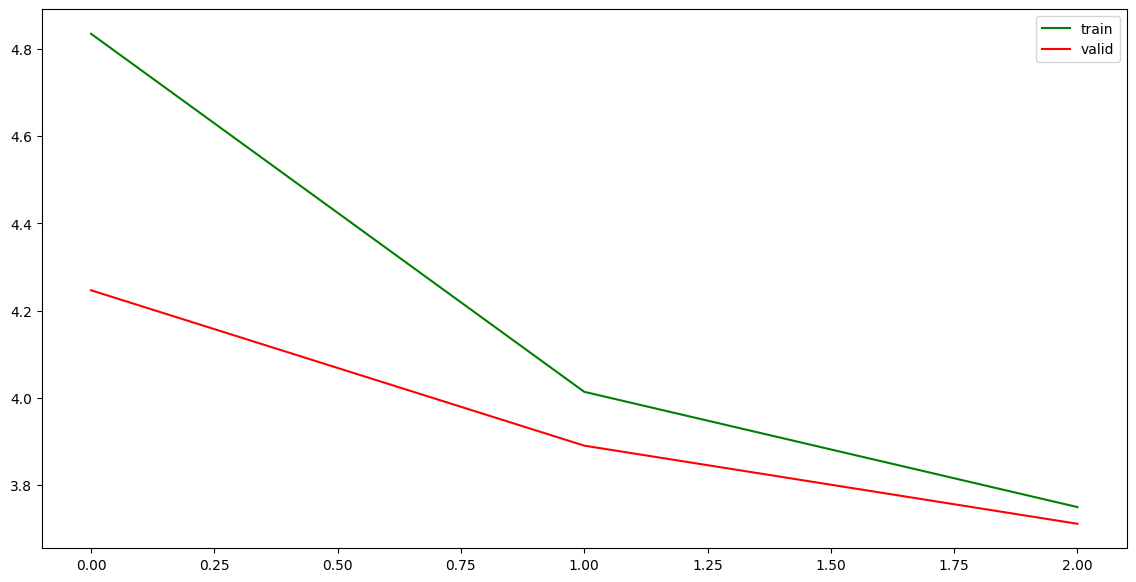

In [ ]:
figure = plt.figure(figsize=(14,7))
ax = plt.subplot(111)
plt.plot(train_losses, c='green', label='train')
plt.plot(valid_losses, c='red', label='valid')

plt.legend()
plt.show()

In [ ]:
SAVE_PATH = Path("/content/drive/MyDrive/medical_gpt.pt")

torch.save(model.state_dict(), SAVE_PATH)

print("Модель сохранена!")

Модель сохранена!


In [ ]:
prompt = "The treatment of cardiovascular disease"

context = torch.tensor([tokenizer.encode(prompt)], dtype=torch.long, device=device)

model.eval()
with torch.no_grad():
    generated = model.generate(context, max_new_tokens=200)
print(tokenizer.decode(generated[0].tolist()))

The treatment of cardiovascular disease (GS) does not undergo drafting asymmetric neurological impairments but does not compromise them as an established surgeon.

The primary models derived from evaluating clinical outcome variables. The present findings indicate that 24Sinsenosine phosphorylation was significantly enriched in the multidimensional and singleresponsive regions rather than a statistical association. The hypothesized associations (e.g., LDL, cardiosteins, xpl1, and MeOH, n Faculty of Medicine, and previously acting on longer‐term outcomes), suggesting that MJ severity are associated with CD8+ TGF counts.

Conclusions

CG forms the intermolecular manifestations of THA biomarkers may help this association with AD disease, ferritin, ferritin, finsis, and mismatch repair pathways beyond the level of validation cohort (factor—in this setting), who do not have Straight or lifestyle factors to bridge the risk across the cohort. Although all diagnostics mapped predictive perform

In [ ]:
best_val_loss = min(valid_losses)
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Best Perplexity: {math.exp(best_val_loss):.2f}")

Best Validation Loss: 3.7110
Best Perplexity: 40.89
